# 5. Does normalizing the ECG help?

Made by `scripts/04_ecg_norm_check.py`. "raw" = MIT-BIH ECG as recorded (mV, with DC offset);
"norm" = zero mean, unit standard deviation. Each mode has its own tuned LMS settings.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # project root, so `src` can be imported

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import FIGURES_DIR, RESULTS_DIR

pd.set_option("display.precision", 2)

In [2]:
t = pd.read_csv(RESULTS_DIR / "ecg_norm_check.csv")
t.groupby(["setup", "method"]).norm_minus_raw.mean().to_frame("mean SNRimp change, norm - raw (dB)")

mean SNRimp change, norm - raw (dB)
setup        method                                          
BW+PLI       EMD+LMS                                     0.38
             EMD+NLMS                                   -1.97
             EMD+RLS                                    -1.20
             LMS, no EMD                                 0.55
BW+PLI+EM+MA PDAF                                        1.50
             PEAF                                        1.56
             SDAF                                       -2.12
             SEAF                                        0.68

In [3]:
t

,method,SNRin_dB,setup,norm,raw,norm_minus_raw
0,EMD+LMS,-5,BW+PLI,18.47,20.33,-1.85
1,EMD+LMS,0,BW+PLI,17.27,17.90,-0.62
2,EMD+LMS,5,BW+PLI,15.13,14.15,0.97
3,EMD+LMS,7,BW+PLI,13.56,12.15,1.42
4,EMD+LMS,10,BW+PLI,11.50,9.52,1.98
5,EMD+NLMS,-5,BW+PLI,9.22,11.11,-1.89
6,EMD+NLMS,0,BW+PLI,4.63,6.57,-1.93
7,EMD+NLMS,5,BW+PLI,-0.30,1.73,-2.03
8,EMD+NLMS,7,BW+PLI,-2.25,-0.26,-1.99
9,EMD+NLMS,10,BW+PLI,-5.09,-3.10,-1.99


## DC offset of the raw ECG

Eq. (4) counts the DC offset as signal power, so with the raw ECG the noise added for a given SNRin is
larger compared with the ECG waveform. `wave_SNR_dB` is the SNR of the waveform alone at SNRin = 10 dB.

In [4]:
pd.read_csv(RESULTS_DIR / "ecg_dc_offset.csv")

,record,mean_mV,std_mV,DC_share_of_power_pct,wave_SNR_dB
0,100,-0.32,0.18,77.40,3.54
1,103,-0.23,0.32,33.26,8.24
2,104,-0.23,0.29,38.04,7.92
3,105,-0.22,0.31,33.33,8.24
4,106,-0.18,0.35,20.29,9.02
5,111,-0.16,0.25,28.56,8.54
6,113,-0.14,0.45,8.78,9.60
7,115,-0.53,0.36,68.56,4.98
8,116,-0.95,0.61,70.45,4.71
9,119,-0.88,0.52,73.90,4.17


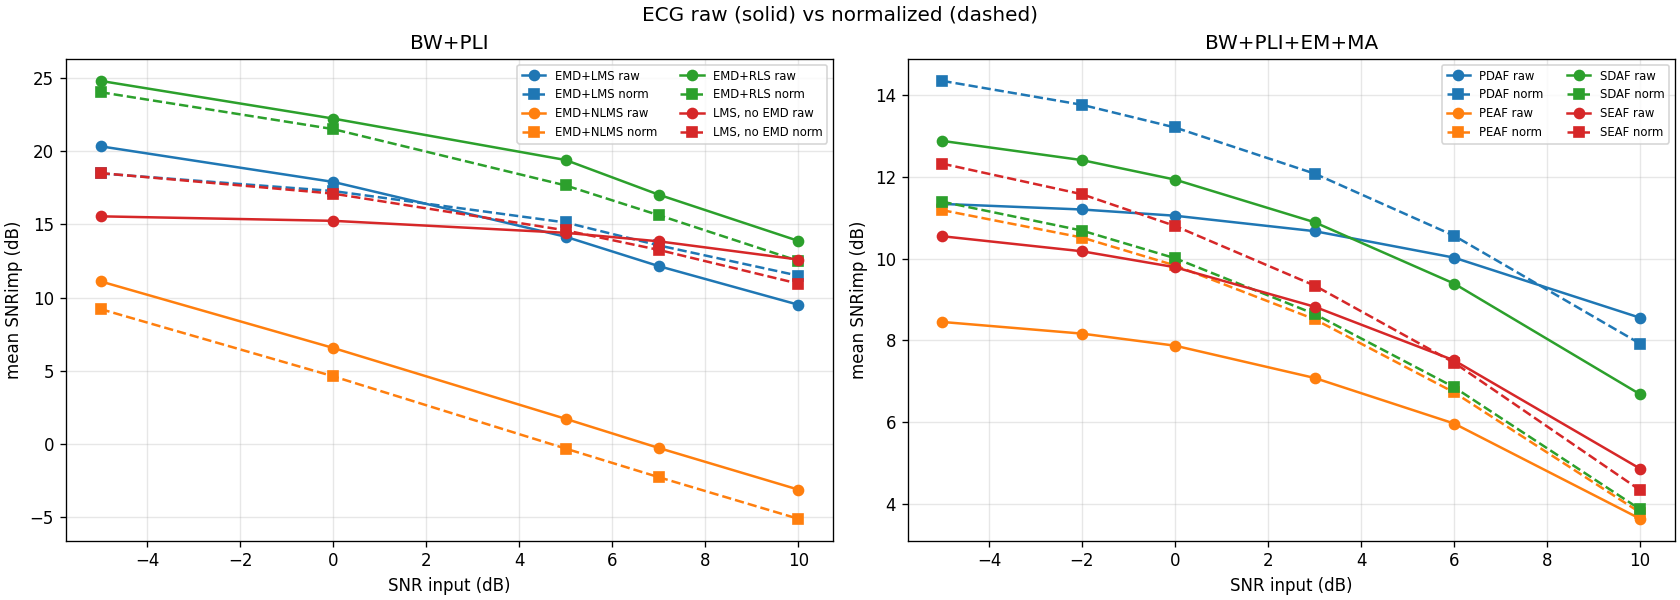

In [5]:
display(Image(FIGURES_DIR / "ecg_norm_check.png"))